# So sánh test bốn mô hình — thiết kế graph × recurrent

Thiết kế 2×2 gồm GRU node-only, GAT-GRU, LSTM node-only và GAT-LSTM. Hai phép đối chứng chính là GAT-GRU so với GRU và GAT-LSTM so với LSTM.

Notebook chỉ đọc prediction artifacts đã khóa, căn chỉnh giao của các cửa sổ test và tính metric hậu nghiệm. Kết luận chính dùng macro-average với trọng số bằng nhau cho MMPP, NHPP, on-off và Pareto.

In [5]:
import importlib
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
while not (ROOT / 'modeling-common').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'modeling-common'))
import forecast_ablation as fa
fa = importlib.reload(fa)

PREDICTIONS = {
    'gru': (ROOT / 'artifacts' / 'gru' /
            'v01_shared_selected_features' / 'gru_node_only_predictions_test.npz'),
    'gatgru': (ROOT / 'artifacts' / 'gatgru' /
               'v05_selected_features_final' / 'gatgru_selected_predictions_test.npz'),
    'lstm': (ROOT / 'artifacts' / 'lstm' /
             'v02_node_only_selected_features' / 'lstm_node_only_predictions_test.npz'),
    'gatlstm': (ROOT / 'artifacts' / 'gatlstm' /
                'v01_shared_selected_features' / 'gatlstm_selected_predictions_test.npz'),
}
missing = [f'{name}: {path}' for name, path in PREDICTIONS.items() if not path.exists()]
if missing:
    raise FileNotFoundError('Run all model notebooks first:\n' + '\n'.join(missing))

OUT = (ROOT / 'artifacts' / 'comparison' /
       'v03_four_models_test')
GRAPH_PAIRS = [('gatgru', 'gru'), ('gatlstm', 'lstm')]
print('output:', OUT)

output: F:\0. UIT\KLTN\thesis-gnn-rl-autoscaling\lstm-load-testing\experiments\comparison\v03_four_models_test


## 1. Căn chỉnh test và tạo toàn bộ metric

Hàm so sánh kiểm tra dataset/split/features/targets, yêu cầu cùng danh sách final seed và chỉ giữ các cửa sổ xuất hiện trong cả bốn artifact.

In [6]:
metrics_by_seed, macro_summary = fa.compare_model_predictions(
    PREDICTIONS,
    OUT,
    graph_pairs=GRAPH_PAIRS,
    make_plots=True,
)
display(macro_summary)

,model,target,MAE_mean,MAE_std,RMSE_mean,RMSE_std,under_MAE_mean,under_MAE_std,over_MAE_mean,over_MAE_std
0,gatgru,cpu_cores,0.012839,0.000151,0.030616,0.000428,0.006858,0.000294,0.005981,0.000275
1,gatgru,rps_in,0.999493,0.012287,2.472591,0.020259,0.611881,0.021584,0.387612,0.011871
2,gatlstm,cpu_cores,0.012728,0.000210,0.031063,0.000541,0.007071,0.000634,0.005657,0.000537
3,gatlstm,rps_in,1.010597,0.017146,2.527781,0.057229,0.616250,0.061859,0.394347,0.050752
4,gru,cpu_cores,0.013231,0.000125,0.031029,0.000200,0.007354,0.000450,0.005877,0.000456
5,gru,rps_in,1.011197,0.000821,2.490443,0.014845,0.602568,0.007187,0.408630,0.007453
6,lstm,cpu_cores,0.013190,0.000310,0.031294,0.000765,0.007040,0.000290,0.006150,0.000437
7,lstm,rps_in,1.003750,0.018153,2.469148,0.048750,0.580832,0.038435,0.422918,0.037525


## 2. Hiệu ứng của GAT và độ chắc chắn theo test run

`mae_improvement_mean > 0` nghĩa là mô hình có GAT có MAE thấp hơn node-only. Sign test dùng bốn cặp test run; 5 seed không được xem là 5 test run độc lập.

In [7]:
display(pd.read_csv(OUT / 'gat_effect_summary.csv'))
display(pd.read_csv(OUT / 'gat_effects_by_test_run.csv'))
display(pd.read_csv(OUT / 'paired_run_sign_test.csv'))

,pair,graph_model,node_only_model,target,mae_improvement_mean,mae_improvement_std_across_seeds,relative_mae_improvement_pct,positive_means_gat_better
0,gatgru_vs_gru,gatgru,gru,cpu_cores,0.000392,0.000118,2.965629,True
1,gatgru_vs_gru,gatgru,gru,rps_in,0.011704,0.012819,1.157422,True
2,gatlstm_vs_lstm,gatlstm,lstm,cpu_cores,0.000462,0.000420,3.502985,True
3,gatlstm_vs_lstm,gatlstm,lstm,rps_in,-0.006847,0.017774,-0.682113,True


,pair,graph_model,node_only_model,run,scenario,target,mae_improvement,positive_means_gat_better
0,gatgru_vs_gru,gatgru,gru,math-load-testing/mmpp/run_04,mmpp,cpu_cores,0.000279,True
1,gatgru_vs_gru,gatgru,gru,math-load-testing/mmpp/run_04,mmpp,rps_in,0.005495,True
2,gatgru_vs_gru,gatgru,gru,math-load-testing/nhpp/run_01,nhpp,cpu_cores,0.000546,True
3,gatgru_vs_gru,gatgru,gru,math-load-testing/nhpp/run_01,nhpp,rps_in,0.020686,True
4,gatgru_vs_gru,gatgru,gru,math-load-testing/onoff/run_06,onoff,cpu_cores,0.000281,True
5,gatgru_vs_gru,gatgru,gru,math-load-testing/onoff/run_06,onoff,rps_in,0.001074,True
6,gatgru_vs_gru,gatgru,gru,math-load-testing/pareto/run_08,pareto,cpu_cores,0.000464,True
7,gatgru_vs_gru,gatgru,gru,math-load-testing/pareto/run_08,pareto,rps_in,0.019561,True
8,gatlstm_vs_lstm,gatlstm,lstm,math-load-testing/mmpp/run_04,mmpp,cpu_cores,0.000977,True
9,gatlstm_vs_lstm,gatlstm,lstm,math-load-testing/mmpp/run_04,mmpp,rps_in,-0.005676,True


,pair,target,gat_wins,test_run_pairs,sign_test_p,mean_node_only_minus_graph_mae
0,gatgru_vs_gru,cpu_cores,4,4,0.125,0.000392
1,gatgru_vs_gru,rps_in,4,4,0.125,0.011704
2,gatlstm_vs_lstm,cpu_cores,4,4,0.125,0.000462
3,gatlstm_vs_lstm,rps_in,2,4,1.000,-0.006847


## 3. MAE theo prediction horizon

Mỗi điểm là MAE macro qua bốn kịch bản; vùng màu là ±1 độ lệch chuẩn qua 5 training seed.

,model,target,horizon_step,horizon_sec,MAE_mean,MAE_std
0,gatgru,cpu_cores,1,10,0.008191,0.000119
1,gatgru,cpu_cores,2,20,0.008494,0.000072
2,gatgru,cpu_cores,3,30,0.010463,0.000136
3,gatgru,cpu_cores,4,40,0.013896,0.000174
4,gatgru,cpu_cores,5,50,0.016842,0.000312
5,gatgru,cpu_cores,6,60,0.019148,0.000353
6,gatgru,rps_in,1,10,0.724660,0.011607
7,gatgru,rps_in,2,20,0.889695,0.009893
8,gatgru,rps_in,3,30,1.000869,0.012732
9,gatgru,rps_in,4,40,1.078457,0.013547


,pair,graph_model,node_only_model,target,horizon_step,horizon_sec,mae_improvement_mean,mae_improvement_std,seed_count,positive_means_gat_better
0,gatgru_vs_gru,gatgru,gru,cpu_cores,1,10,0.000204,0.000238,5,True
1,gatgru_vs_gru,gatgru,gru,cpu_cores,2,20,0.000521,0.000152,5,True
2,gatgru_vs_gru,gatgru,gru,cpu_cores,3,30,0.000524,0.000098,5,True
3,gatgru_vs_gru,gatgru,gru,cpu_cores,4,40,0.000466,0.000139,5,True
4,gatgru_vs_gru,gatgru,gru,cpu_cores,5,50,0.000361,0.000180,5,True
5,gatgru_vs_gru,gatgru,gru,cpu_cores,6,60,0.000278,0.000284,5,True
6,gatgru_vs_gru,gatgru,gru,rps_in,1,10,0.025632,0.004981,5,True
7,gatgru_vs_gru,gatgru,gru,rps_in,2,20,0.002657,0.016258,5,True
8,gatgru_vs_gru,gatgru,gru,rps_in,3,30,0.006077,0.011692,5,True
9,gatgru_vs_gru,gatgru,gru,rps_in,4,40,0.005931,0.019280,5,True


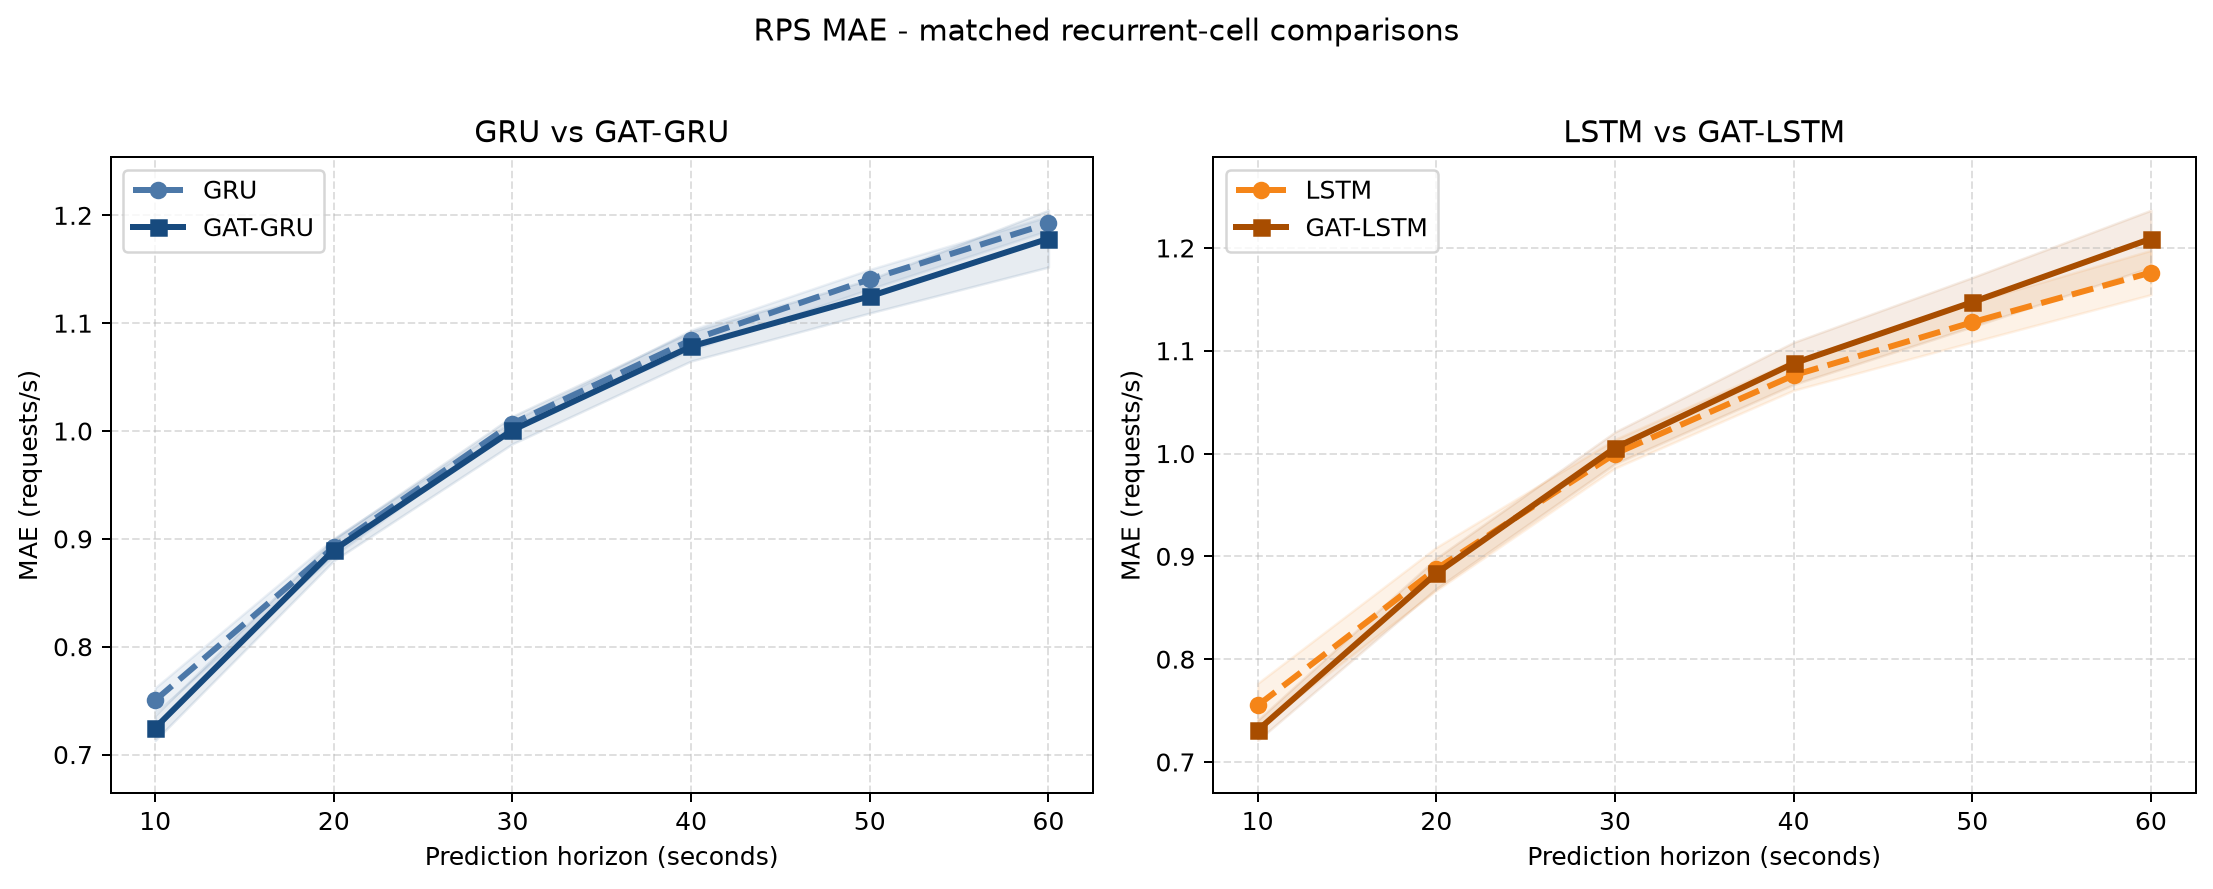

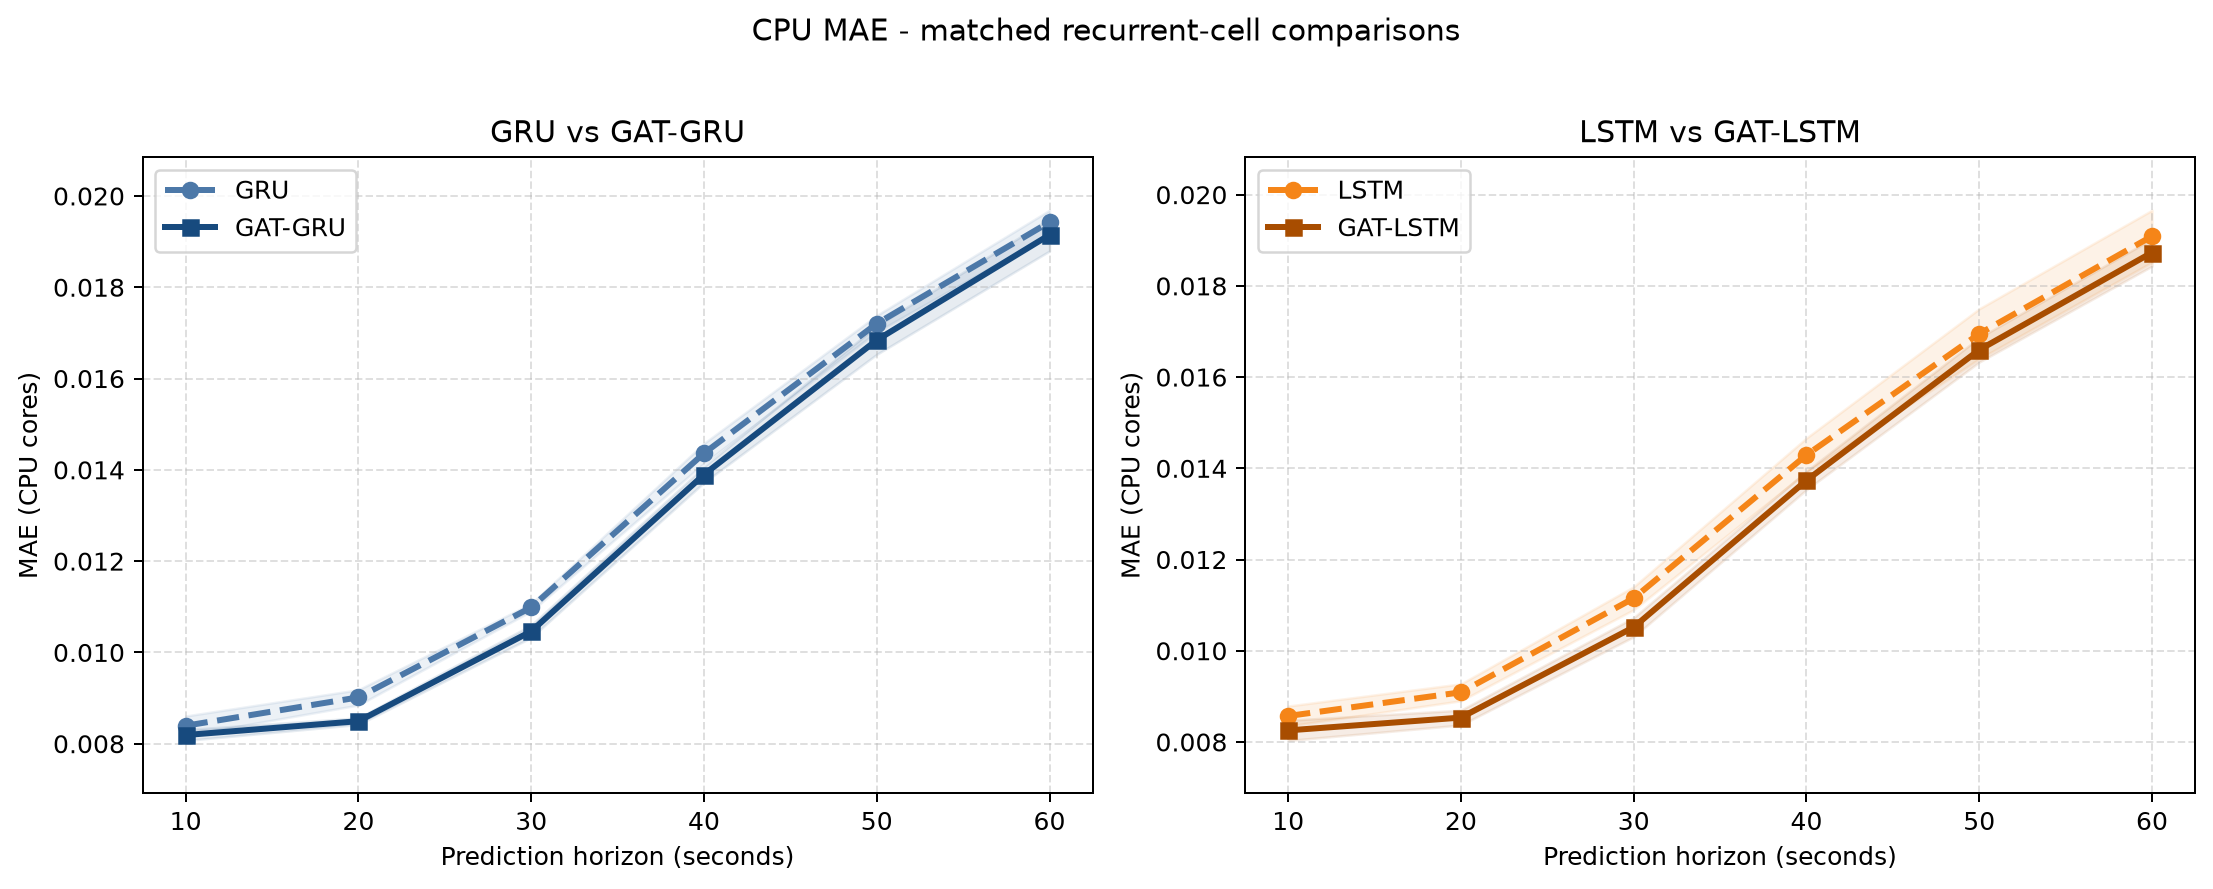

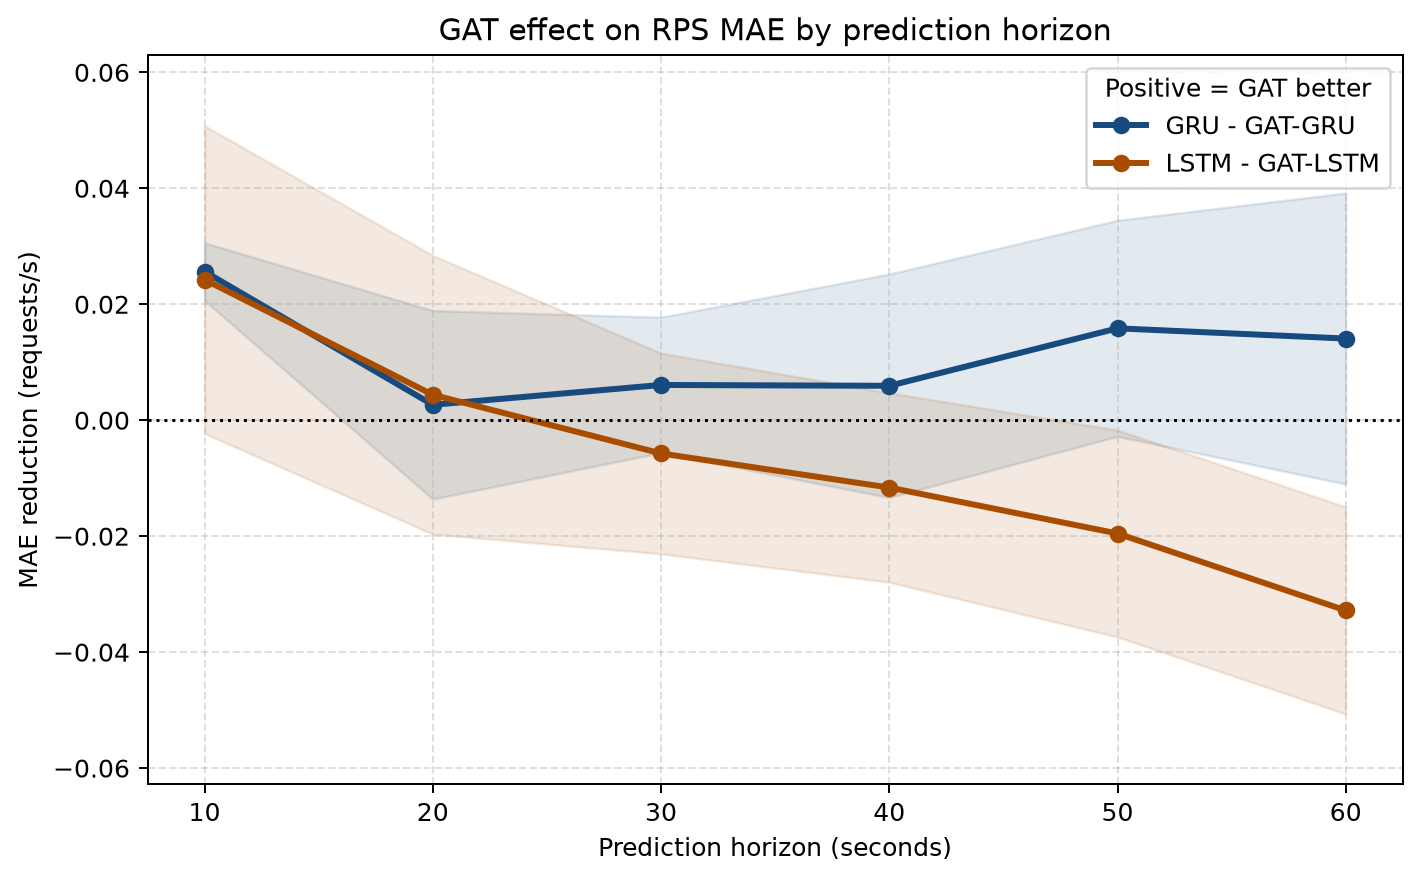

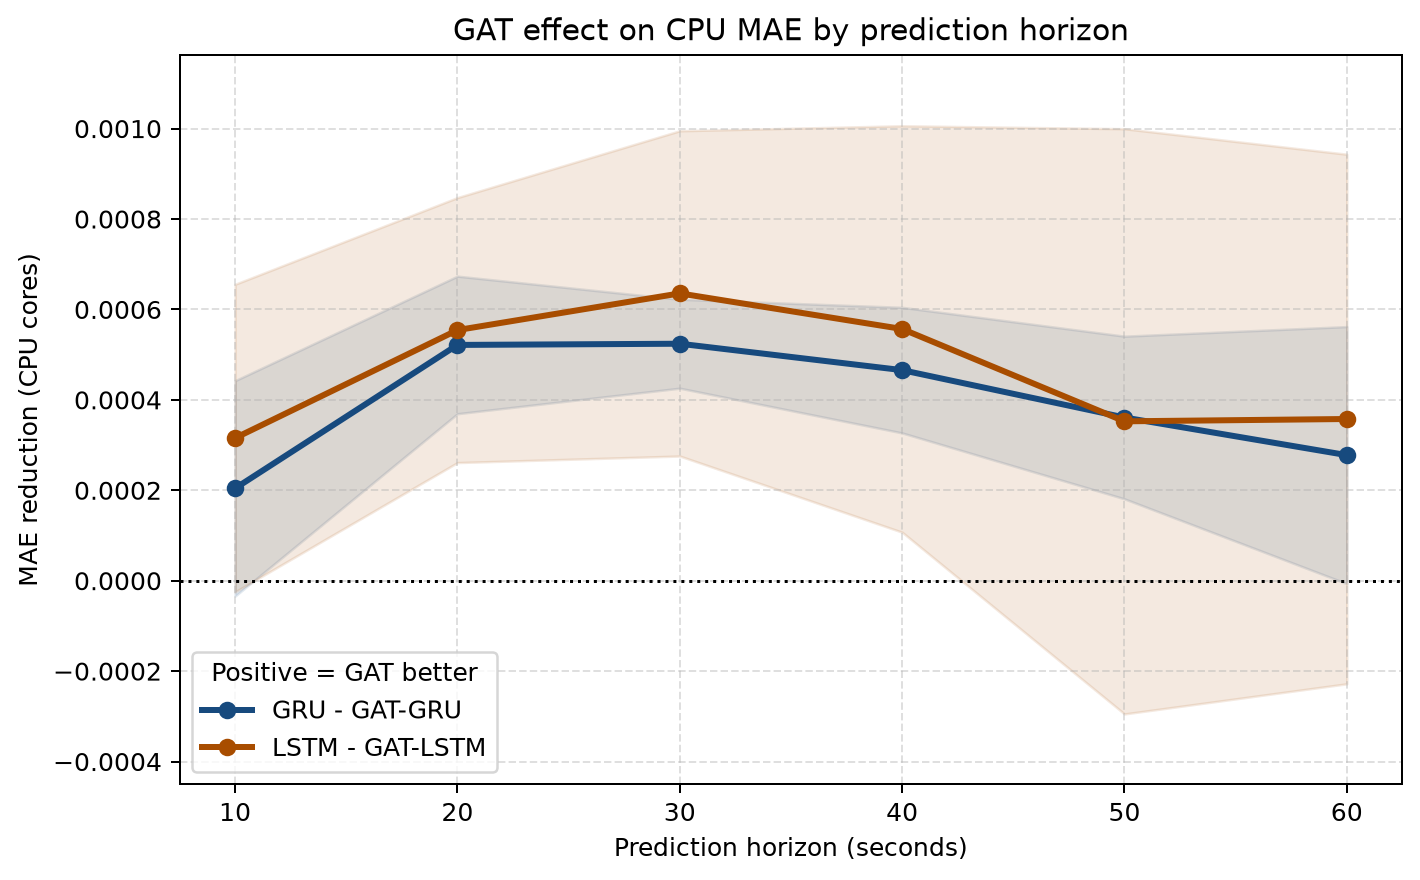

In [8]:
display(pd.read_csv(OUT / 'metrics_by_horizon_macro.csv'))
display(pd.read_csv(OUT / 'gat_effects_by_horizon.csv'))

# Pairwise panels are easier to read than the four-line overview.
display(Image(filename=str(OUT / 'mae_by_horizon_rps_in_paired.png')))
display(Image(filename=str(OUT / 'mae_by_horizon_cpu_cores_paired.png')))

# Positive values mean that adding GAT reduced MAE.
display(Image(filename=str(OUT / 'gat_effect_by_horizon_rps_in.png')))
display(Image(filename=str(OUT / 'gat_effect_by_horizon_cpu_cores.png')))